In [17]:
# Настройка проекта
import matplotlib.pyplot as plt
import meep as mp
import conf
import torch
from lib import adjoint as mpa
from lib import torch_functions as tf
from lib import numpy_functions as nf
from lib import my_gui, my_decoders, my_sources
from lib import help_functions
from autograd import numpy as npa
import numpy as np
mp.verbosity(0) # decrease amount of output

def plot_efficiency_vs_angle(angles_deg, mean_values, std_values, title="Focusing efficiency"):
    """
    angles_deg : list or np.ndarray
        Углы в градусах (ось X)
    mean_values : list or np.ndarray
        Средние значения эффективности для каждого угла
    std_values : list or np.ndarray
        Стандартное отклонение для каждого угла
    """
    plt.figure(figsize=(8, 5))
    
    # график с погрешностями
    plt.errorbar(
        angles_deg, mean_values, yerr=std_values,
        fmt='o-', capsize=5, elinewidth=1, markerfacecolor='blue', color='black'
    )
    
    plt.xlabel("Angel, degrees")
    plt.ylabel("Efficiency")
    plt.title(title)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.show()

def plot_efficiency_vs_angle_with_wavelengths(angles_deg, kpd_values, wavelengths, title="Focusing efficiency"):
    """
    angles_deg : list or np.ndarray
        Углы в градусах (ось X)
    kpd_values : 2D list or np.ndarray
        Значения эффективности: shape = (n_angles, n_wavelengths)
    wavelengths : list or np.ndarray
        Список длин волн, соответствует второй размерности kpd_values
    """
    kpd_values = np.array(kpd_values)
    mean_vals = np.mean(kpd_values, axis=1)
    var_val = np.var(kpd_values)     
    std_vals  = np.std(kpd_values, axis=1)
    print(f"mean_vals: {mean_vals}", f"std_vals: {std_vals}, var_val: {var_val}")

    plt.figure(figsize=(9, 6))

    # --- 1. точки для каждой длины волны ---
    for j, wl in enumerate(wavelengths):
        plt.scatter(
            angles_deg,
            kpd_values[:, j],
            label=f"λ = {wl} μm",
            s=50  # размер маркеров
        )

    # --- 2. линия среднего со стандартным отклонением ---
    plt.errorbar(
        angles_deg, mean_vals, yerr=std_vals,
        fmt="k-o", capsize=5, elinewidth=1.2, linewidth=2,
        label="average ± σ"
    )

    plt.xlabel("Angel, degrees")
    plt.ylabel("Efficiency")
    plt.title(title)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.show()
    
def plot_efficiency_vs_penalty_with_wavelengths(penalty, kpd_values, wavelengths, title="Focusing efficiency"):
    """
    penalty : list or np.ndarray
        penalty (ось X)
    kpd_values : 2D list or np.ndarray
        Значения эффективности: shape = (n_angles, n_wavelengths)
    wavelengths : list or np.ndarray
        Список длин волн, соответствует второй размерности kpd_values
    """
    kpd_values = np.array(kpd_values)
    mean_vals = np.mean(kpd_values, axis=1)
    var_val = np.var(kpd_values)     
    std_vals  = np.std(kpd_values, axis=1)
    print(f"mean_vals: {mean_vals}", f"std_vals: {std_vals}, var_val: {var_val}")

    plt.figure(figsize=(9, 6))

    # --- 1. точки для каждой длины волны ---
    for j, wl in enumerate(wavelengths):
        plt.scatter(
            penalty,
            kpd_values[:, j],
            label=f"λ = {wl} μm",
            s=50  # размер маркеров
        )

    # --- 2. линия среднего со стандартным отклонением ---
    plt.errorbar(
        penalty, mean_vals, yerr=std_vals,
        fmt="k-o", capsize=5, elinewidth=1.2, linewidth=2,
        label="average ± σ"
    )

    plt.xlabel("Penalty coefficient")
    plt.ylabel("Efficiency")
    plt.title(title)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.show()

# pure_kpd = [0.35947390054564643, 0.2767026404398865, 0.28535518970266416, 0.44443450969222864, 0.5927641479315569, 0.531265898104135]
# std = [0.219, 0.145, 0.190, 0.042, 0.164, 0.214]
# plot_efficiency_vs_angle(angles, pure_kpd, std)

In [18]:
kpd_set  = [
    [0.50418541, 0.28890397, 0.81205708],
    [0.54761979, 0.29797414, 0.7549601],
    [0.57372324, 0.32106635, 0.72222582], 
    [0.58998085, 0.36587542, 0.69215732],
]

In [20]:
angles = conf.angle_list
waves = conf.inc_wavelength_array
penalty = [0, 5, 10, 20]
# plot_efficiency_vs_angle_with_wavelengths(angles, kpd_set, waves)

mean_vals: [0.53504882 0.53351801 0.53900514 0.54933786] std_vals: [0.21468847 0.18683002 0.16560242 0.136269  ], var_val: 0.03178558091697927


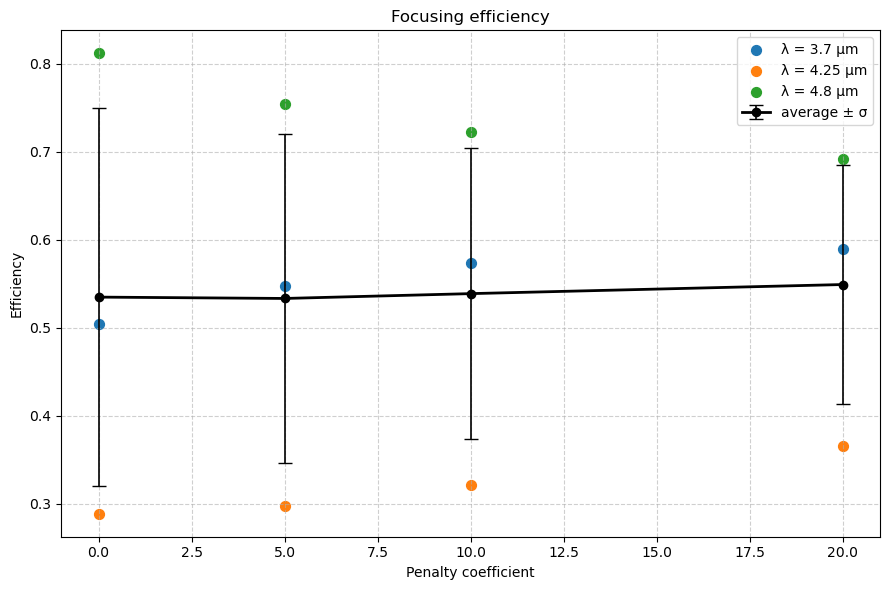

In [21]:
plot_efficiency_vs_penalty_with_wavelengths(penalty, kpd_set, waves)